# Bias–Variance Tradeoff: Underfitting and Overfitting

A quick, visual introduction to one of the central ideas in machine learning: **why a model can be too simple, too complex, or just right.**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

BLUE, DARK_BLUE, ORANGE = "#2a78d6", "#184f95", "#eb6834"
INK, DARK_GRAY, GRAY = "#0b0b0b", "#52514e", "#898781"
YELLOW, GREEN, RED = "#eda100", "#0ca30c", "#e34948"

plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7",
    "axes.grid": True,
    "grid.color": "#e1e0d9",
    "axes.titleweight": "bold",
    "legend.frameon": False,
})

## 1. Bias and Variance: The Big Picture

Imagine we could repeat the whole experiment many times: collect a new training set, train the model, and make a prediction at some point $x$. Every run gives a slightly different model. Two different things can go wrong:

- **Bias**: error from wrong assumptions. If the model is too simple (e.g. a straight line for curved data), it is wrong *on average*, no matter which training set it sees.
- **Variance**: error from sensitivity to the particular training set. If the model is too flexible, small changes in the training data produce very different models.

For squared error, the expected test error at a point $x$ splits into exactly three parts:

$$
\mathbb{E}\left[\big(y - \hat{f}(x)\big)^2\right]
= \underbrace{\big(\mathbb{E}[\hat{f}(x)] - f(x)\big)^2}_{\text{Bias}^2}
+ \underbrace{\mathbb{E}\left[\big(\hat{f}(x) - \mathbb{E}[\hat{f}(x)]\big)^2\right]}_{\text{Variance}}
+ \underbrace{\sigma^2}_{\text{irreducible noise}}
$$

- $f(x)$ is the true function, $\hat{f}(x)$ is the model's prediction, and $\mathbb{E}$ averages over many possible training sets.
- $\sigma^2$ is the noise in the data itself. No model can remove it.

Making a model more complex usually **lowers the bias but raises the variance**. That is the **tradeoff**: we look for the complexity where the *sum* of the two is smallest.

The classic way to picture this is a dartboard. The bullseye is the true value; each dart is the prediction of a model trained on a different training set.

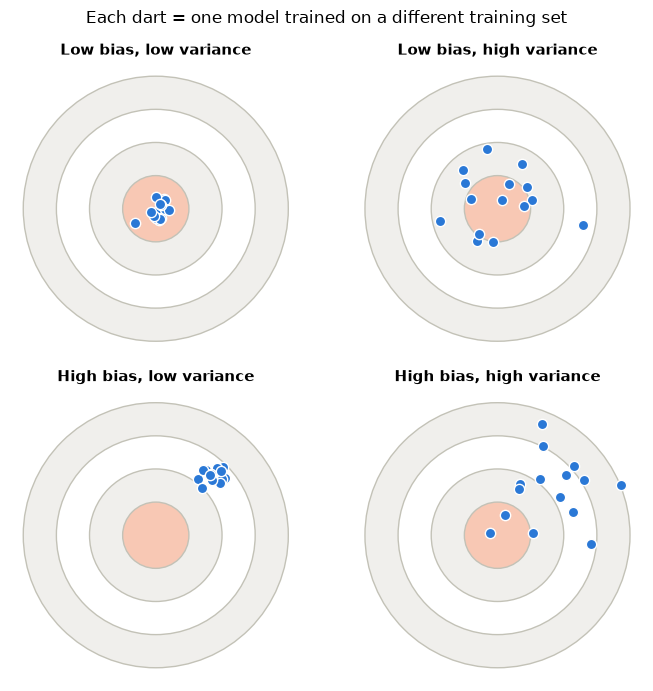

In [ ]:
rng = np.random.default_rng(42)
cases = [  
    ("Low bias, low variance",   0.00, 0.08),
    ("Low bias, high variance",  0.00, 0.30),
    ("High bias, low variance",  0.45, 0.08),
    ("High bias, high variance", 0.45, 0.30),
]

fig, axes = plt.subplots(2, 2, figsize=(7, 7))
for ax, (title, bias, spread) in zip(axes.flat, cases):
    for radius, color in zip([1.0, 0.75, 0.5, 0.25], ["#f0efec", "white", "#f0efec", "#f8c8b4"]):
        ax.add_patch(plt.Circle((0, 0), radius, facecolor=color, edgecolor="#c3c2b7"))
    darts = rng.normal(loc=bias, scale=spread, size=(15, 2))
    ax.scatter(darts[:, 0], darts[:, 1], color=BLUE, edgecolor="white", s=55, zorder=3)
    ax.set_title(title, fontsize=11)
    ax.set(xlim=(-1.1, 1.1), ylim=(-1.1, 1.1), aspect="equal")
    ax.axis("off")

fig.suptitle("Each dart = one model trained on a different training set")
plt.tight_layout()
plt.show()

- **High bias, low variance**: darts are tightly grouped but off-center → **underfitting**.
- **Low bias, high variance**: darts are centered on average but scattered → **overfitting**.
- **Low bias, low variance**: what we want.

The rest of the notebook shows what these situations look like for a real regression model.

## 2. The Dataset

Throughout the notebook we use data generated from a known **cubic polynomial** plus Gaussian noise:

$$
y = f(x) + \varepsilon, \qquad f(x) = 3x^3 + 2x^2 - 2x, \qquad \varepsilon \sim \mathcal{N}(0,\ 0.3^2)
$$

Because we generated the data ourselves, we know the true $f(x)$ (dashed line) and can see exactly how far each model is from it. In real problems $f$ is unknown.

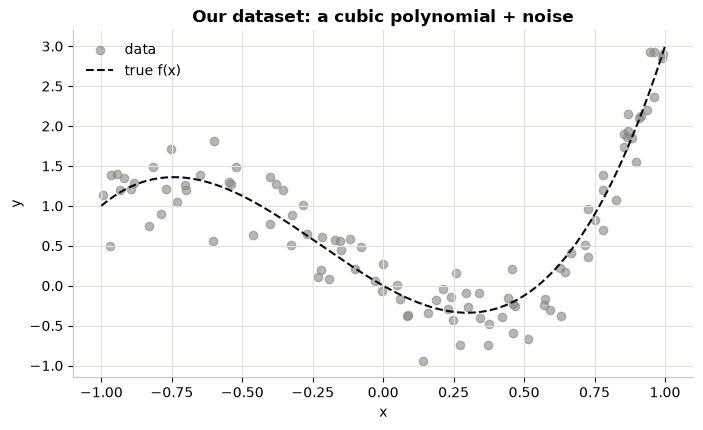

In [3]:
def true_function(x):
    return 3 * x**3 + 2 * x**2 - 2 * x


def make_data(n, noise=0.3, seed=None):
    # Sample n points with x uniform in [-1, 1] and y = f(x) + Gaussian noise.
    rng = np.random.default_rng(seed)
    x = rng.uniform(-1, 1, n)
    y = true_function(x) + rng.normal(0, noise, n)
    return x, y


x_grid = np.linspace(-1, 1, 300)  # dense grid, used only to draw smooth curves


def plot_truth(ax):
    ax.plot(x_grid, true_function(x_grid), "--", color=INK, lw=1.5, label="true f(x)")


x, y = make_data(100, seed=0)

fig, ax = plt.subplots()
ax.scatter(x, y, color=GRAY, alpha=0.6, label="data")
plot_truth(ax)
ax.set(title="Our dataset: a cubic polynomial + noise", xlabel="x", ylabel="y")
ax.legend()
plt.show()

## 3. Underfitting: A Straight Line on a Curve

Plain linear regression, $\hat{y} = w x + b$, can only draw straight lines. Our data is curved, so **no choice** of $w$ and $b$ can fit it well. The model is **too simple**: this is **underfitting** (high bias).

Training MSE of the straight line: 0.834


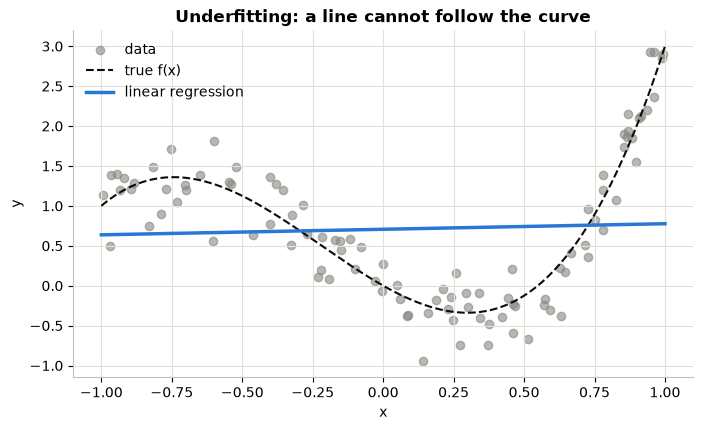

In [ ]:
linear_model = LinearRegression()
linear_model.fit(x.reshape(-1, 1), y)

y_line = linear_model.predict(x_grid.reshape(-1, 1))
mse_line = mean_squared_error(y, linear_model.predict(x.reshape(-1, 1)))
print(f"Training MSE of the straight line: {mse_line:.3f}")

fig, ax = plt.subplots()
ax.scatter(x, y, color=GRAY, alpha=0.6, label="data")
plot_truth(ax)
ax.plot(x_grid, y_line, color=BLUE, lw=2.5, label="linear regression")
ax.set(title="Underfitting: a line cannot follow the curve", xlabel="x", ylabel="y")
ax.legend()
plt.show()

Note that the **training error itself is high**. An underfitting model is bad even on the data it was trained on, so more data or longer training will not help. The model needs more **capacity**.

## 4. Fixing Underfitting with Feature Engineering

We do not need a new algorithm. We can give linear regression **better features**. Instead of the raw input $x$, we feed it powers of $x$:

$$
\phi(x) = [\,x,\ x^2,\ x^3\,] \qquad \Longrightarrow \qquad \hat{y} = w_1 x + w_2 x^2 + w_3 x^3 + b
$$

The model is still **linear in the weights** $w$ (so it is still ordinary linear regression), but it is now a **cubic curve in $x$**.

In [5]:
def polynomial_features(x, degree):
    # Map x -> [x, x^2, ..., x^degree], one column per power.
    return np.column_stack([x**k for k in range(1, degree + 1)])


X_cubic = polynomial_features(x, degree=3)

print("Original feature x (first 5 rows):")
print(np.round(x[:5].reshape(-1, 1), 3))
print("\nEngineered features [x, x^2, x^3] (first 5 rows):")
print(np.round(X_cubic[:5], 3))

Original feature x (first 5 rows):
[[ 0.274]
 [-0.46 ]
 [-0.918]
 [-0.967]
 [ 0.627]]

Engineered features [x, x^2, x^3] (first 5 rows):
[[ 0.274  0.075  0.021]
 [-0.46   0.212 -0.098]
 [-0.918  0.843 -0.774]
 [-0.967  0.935 -0.904]
 [ 0.627  0.393  0.246]]


Learned weights [w1, w2, w3]: [-2.22  1.99  3.31]   bias: -0.02
True weights    [w1, w2, w3]: [-2.  2.  3.]   bias: 0

Training MSE  straight line: 0.834
Training MSE  cubic model:   0.082   (noise variance σ² = 0.09)


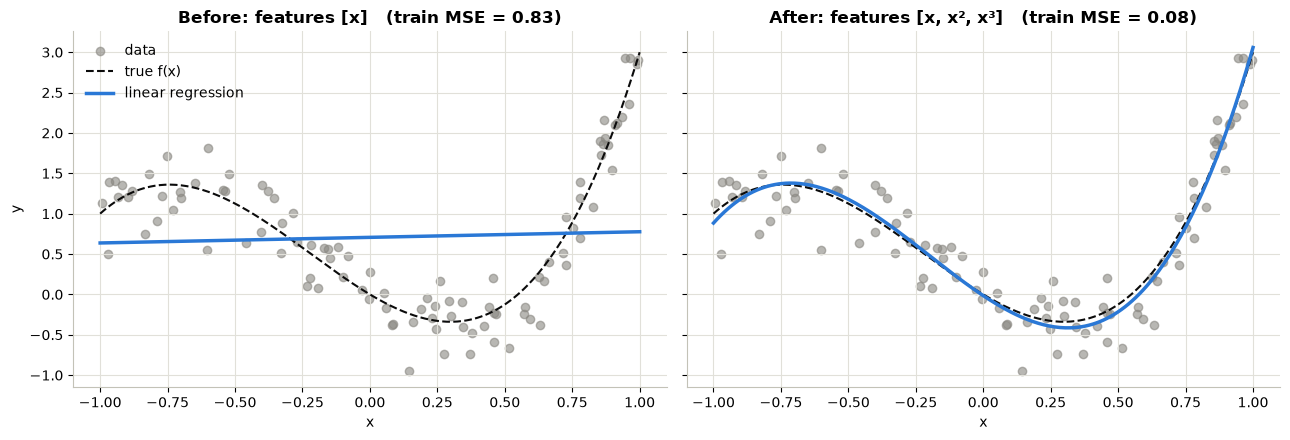

In [6]:
cubic_model = LinearRegression().fit(X_cubic, y)  # the same linear regression, new features

y_curve = cubic_model.predict(polynomial_features(x_grid, 3))
mse_cubic = mean_squared_error(y, cubic_model.predict(X_cubic))

print("Learned weights [w1, w2, w3]:", np.round(cubic_model.coef_, 2), "  bias:", round(cubic_model.intercept_, 2))
print("True weights    [w1, w2, w3]: [-2.  2.  3.]   bias: 0")
print(f"\nTraining MSE  straight line: {mse_line:.3f}")
print(f"Training MSE  cubic model:   {mse_cubic:.3f}   (noise variance σ² = 0.09)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
panels = [
    (y_line, f"Before: features [x]   (train MSE = {mse_line:.2f})"),
    (y_curve, f"After: features [x, x², x³]   (train MSE = {mse_cubic:.2f})"),
]
for ax, (curve, title) in zip(axes, panels):
    ax.scatter(x, y, color=GRAY, alpha=0.6, label="data")
    plot_truth(ax)
    ax.plot(x_grid, curve, color=BLUE, lw=2.5, label="linear regression")
    ax.set(title=title, xlabel="x")
axes[0].set_ylabel("y")
axes[0].legend()
plt.tight_layout()
plt.show()

With the right features, the model recovers weights very close to the true ones, and its curve sits almost on top of $f(x)$. Its training MSE is now close to the noise variance $\sigma^2 = 0.09$, which is the best any model can do on new data.

## 5. Overfitting: Memorizing the Noise

If adding features helped, why not add *many* features? Let's give the model all powers up to $x^{14}$ and train it on a **small training set of 15 points**. With 15 parameters (14 weights + bias) for 15 points, the model can pass **exactly through every training point**, noise included.

To find out whether a model learned the real pattern, we evaluate it on **test data** that it never saw during training.

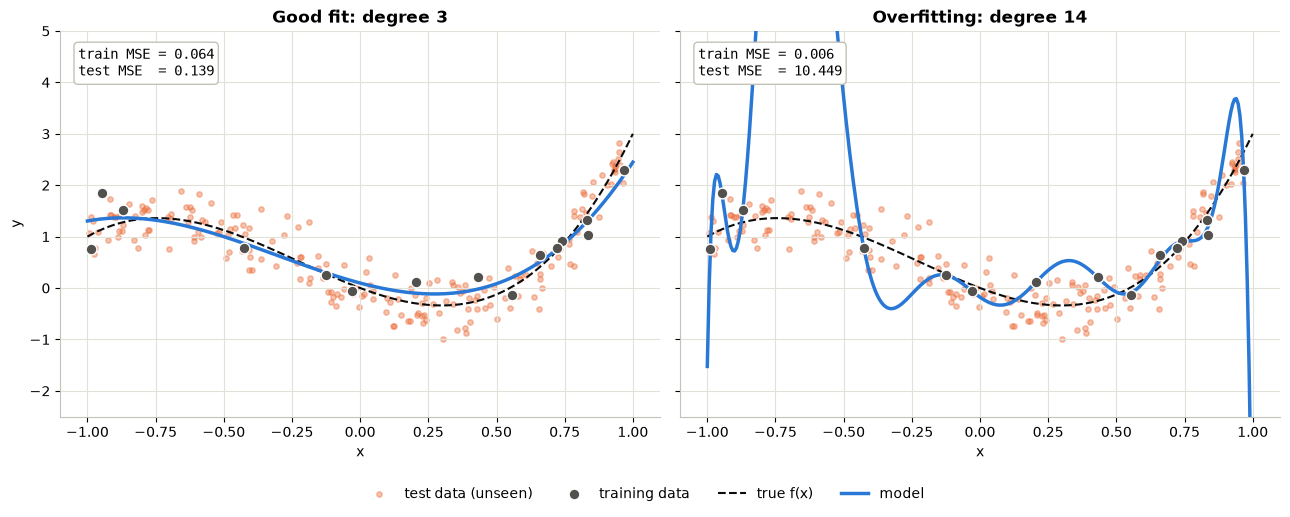

In [7]:
def predict(model, x):
    degree = model.n_features_in_  # the number of features is the polynomial degree
    return model.predict(polynomial_features(x, degree))


x_train, y_train = make_data(15, seed=9)
x_test, y_test = make_data(200, seed=2)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, degree, title in zip(axes, [3, 14], ["Good fit: degree 3", "Overfitting: degree 14"]):
    model = LinearRegression().fit(polynomial_features(x_train, degree), y_train)
    train_mse = mean_squared_error(y_train, predict(model, x_train))
    test_mse = mean_squared_error(y_test, predict(model, x_test))

    ax.scatter(x_test, y_test, color=ORANGE, alpha=0.4, s=15, label="test data (unseen)")
    ax.scatter(x_train, y_train, color=DARK_GRAY, edgecolor="white", s=60, zorder=3, label="training data")
    plot_truth(ax)
    ax.plot(x_grid, predict(model, x_grid), color=BLUE, lw=2.5, label=f"degree-{degree} model")
    ax.text(0.03, 0.96, f"train MSE = {train_mse:.3f}\ntest MSE  = {test_mse:.3f}",
            transform=ax.transAxes, va="top", family="monospace",
            bbox=dict(facecolor="white", edgecolor="#c3c2b7", boxstyle="round"))
    ax.set(title=title, xlabel="x", ylim=(-2.5, 5))
axes[0].set_ylabel("y")
handles, labels = axes[1].get_legend_handles_labels()
labels[-1] = "model"
fig.legend(handles, labels, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 0.0))
plt.tight_layout()
plt.show()

The degree-14 model has almost **zero training error** but a test error that is many times larger. It memorized the 15 training points (including their noise) instead of learning $f(x)$.

Typical signs of overfitting:
- very low training error, but much higher test error (a large **generalization gap**);
- a wiggly curve that swings wildly between and beyond the training points.

## 6. Variance: Same Model, Different Training Sets

Bias and variance describe what happens **across different training sets**. Let's run the dartboard experiment from Section 1 for real:

1. Take one dataset of 500 points.
2. Draw 25 different random training sets (25 points each) from it.
3. Train the same kind of model on each one and plot all 25 curves together.

We repeat this for three complexities: degree 1 (too simple), degree 3 (right), and degree 10 (too complex). All three use the **same** 25 training sets, so the only difference between the panels is the model complexity.

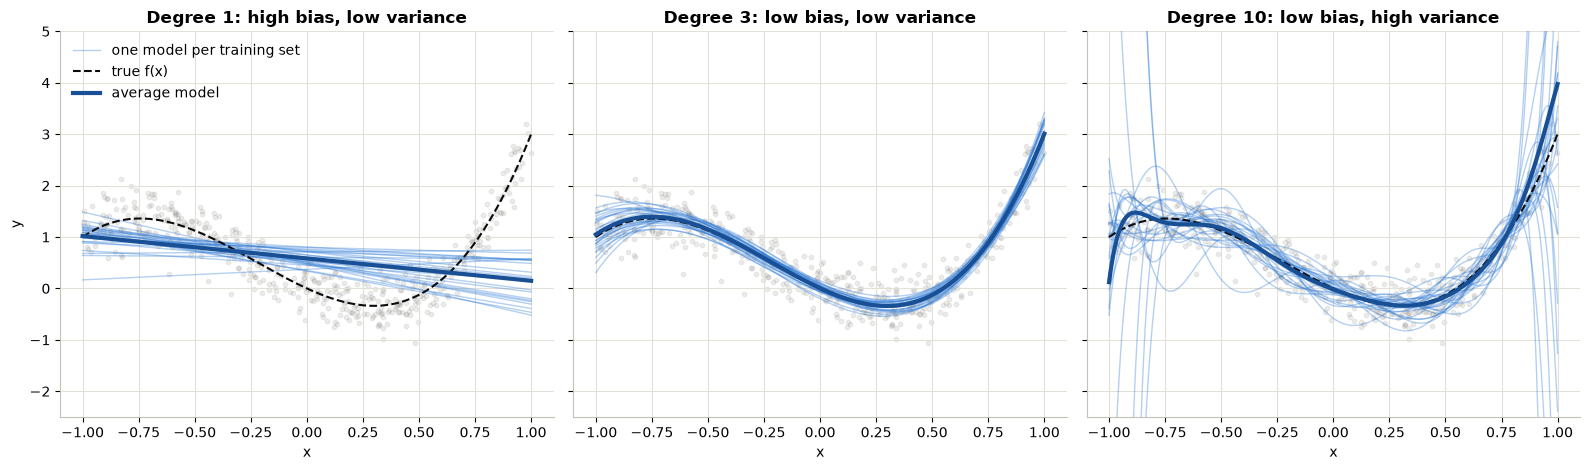

In [8]:
x_pool, y_pool = make_data(500, seed=3)  # one fixed dataset
n_models, n_train = 25, 25

settings = [
    (1, "Degree 1: high bias, low variance"),
    (3, "Degree 3: low bias, low variance"),
    (10, "Degree 10: low bias, high variance"),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
for ax, (degree, title) in zip(axes, settings):
    rng = np.random.default_rng(2)  # same seed -> every panel gets the same 25 training sets
    ax.scatter(x_pool, y_pool, color=GRAY, alpha=0.15, s=10)
    predictions = []
    for i in range(n_models):
        idx = rng.choice(len(x_pool), size=n_train, replace=False)  # a new random training set
        model = LinearRegression().fit(polynomial_features(x_pool[idx], degree), y_pool[idx])
        predictions.append(predict(model, x_grid))
        ax.plot(x_grid, predictions[-1], color=BLUE, alpha=0.35, lw=1,
                label="one model per training set" if i == 0 else None)
    plot_truth(ax)
    ax.plot(x_grid, np.mean(predictions, axis=0), color=DARK_BLUE, lw=3, label="average model")
    ax.set(title=title, xlabel="x", ylim=(-2.5, 5))
axes[0].set_ylabel("y")
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()

- **Degree 1**: the 25 lines agree with each other (**low variance**), but they are all wrong in the same way (**high bias**). Their average is still a straight line.
- **Degree 3**: the curves agree with each other *and* with the truth: low bias and low variance.
- **Degree 10**: each individual curve is very different, especially near the edges, where there are few training points. The model depends heavily on which 25 points it happened to see (**high variance**). Yet the *average* of the models follows the truth closely (**low bias**): the true cubic is a special case of a degree-10 polynomial, so on average the model gets it right. Any single model, though, can be far off.

## 7. Train vs. Test Loss: Finding the Sweet Spot

Finally, let's sweep the model complexity (polynomial degree from 1 to 12) and measure the **training** and **test** error of each model. For a smooth picture we repeat the experiment over 100 random train/test splits of the dataset (20 training points each) and take the **median** error. The median is not thrown off by the few splits where a high-degree model explodes.

In [9]:
degrees = np.arange(1, 13)
n_splits, n_train = 100, 20
rng = np.random.default_rng(0)

train_loss, test_loss = [], []
for degree in degrees:
    train_errors, test_errors = [], []
    for _ in range(n_splits):
        idx = rng.permutation(len(x_pool))
        tr, te = idx[:n_train], idx[n_train:]  # 20 training points, the rest is test data
        model = LinearRegression().fit(polynomial_features(x_pool[tr], degree), y_pool[tr])
        train_errors.append(mean_squared_error(y_pool[tr], predict(model, x_pool[tr])))
        test_errors.append(mean_squared_error(y_pool[te], predict(model, x_pool[te])))
    train_loss.append(np.median(train_errors))
    test_loss.append(np.median(test_errors))

train_loss, test_loss = np.array(train_loss), np.array(test_loss)
for d, tr_l, te_l in zip(degrees, train_loss, test_loss):
    print(f"degree {d:2d}:  train MSE = {tr_l:7.3f}   test MSE = {te_l:8.3f}")

degree  1:  train MSE =   0.502   test MSE =    0.639
degree  2:  train MSE =   0.211   test MSE =    0.326
degree  3:  train MSE =   0.069   test MSE =    0.108
degree  4:  train MSE =   0.062   test MSE =    0.119
degree  5:  train MSE =   0.062   test MSE =    0.131
degree  6:  train MSE =   0.052   test MSE =    0.177
degree  7:  train MSE =   0.054   test MSE =    0.274
degree  8:  train MSE =   0.047   test MSE =    0.405
degree  9:  train MSE =   0.042   test MSE =    0.997
degree 10:  train MSE =   0.041   test MSE =    6.504
degree 11:  train MSE =   0.033   test MSE =  113.679
degree 12:  train MSE =   0.030   test MSE =  237.249


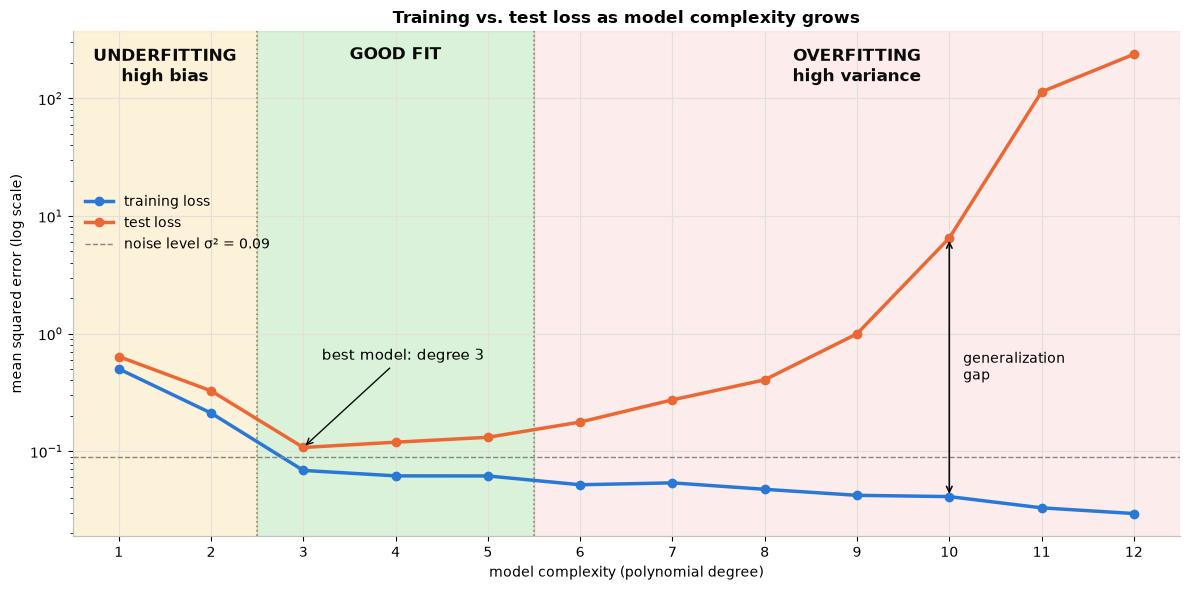

In [10]:
best = degrees[np.argmin(test_loss)]
good = degrees[test_loss <= 1.25 * test_loss.min()]  # degrees whose test loss is close to the best
left, right = good.min() - 0.5, good.max() + 0.5
x_min, x_max = degrees[0] - 0.5, degrees[-1] + 0.5

fig, ax = plt.subplots(figsize=(12, 6))

# Shaded regions
ax.axvspan(x_min, left, color=YELLOW, alpha=0.15)
ax.axvspan(left, right, color=GREEN, alpha=0.15)
ax.axvspan(right, x_max, color=RED, alpha=0.10)
for boundary in (left, right):
    ax.axvline(boundary, color=GRAY, ls=":", lw=1.2)
regions = [
    ((x_min + left) / 2, "UNDERFITTING\nhigh bias"),
    ((left + right) / 2, "GOOD FIT"),
    ((right + x_max) / 2, "OVERFITTING\nhigh variance"),
]
for x_mid, text in regions:
    ax.text(x_mid, 0.97, text, transform=ax.get_xaxis_transform(),
            ha="center", va="top", fontsize=12, fontweight="bold", color=INK)

# Loss curves
ax.plot(degrees, train_loss, "o-", color=BLUE, lw=2.5, label="training loss")
ax.plot(degrees, test_loss, "o-", color=ORANGE, lw=2.5, label="test loss")
ax.axhline(0.09, color=GRAY, ls="--", lw=1, label="noise level σ² = 0.09")

# Annotations
ax.annotate(f"best model: degree {best}", xy=(best, test_loss.min()), xytext=(best + 0.2, 0.6),
            arrowprops=dict(arrowstyle="->", color=INK), fontsize=11)
d = 10
ax.annotate("", xy=(d, test_loss[d - 1]), xytext=(d, train_loss[d - 1]),
            arrowprops=dict(arrowstyle="<->", color=INK, lw=1.2))
ax.text(d + 0.15, np.sqrt(test_loss[d - 1] * train_loss[d - 1]), "generalization\ngap", va="center", fontsize=10)

ax.set_yscale("log")
ax.set(title="Training vs. test loss as model complexity grows",
       xlabel="model complexity (polynomial degree)", ylabel="mean squared error (log scale)",
       xticks=degrees, xlim=(x_min, x_max))
ax.legend(loc="center left", bbox_to_anchor=(0.0, 0.62))
plt.tight_layout()
plt.show()

How to read this plot:

- **Training loss always goes down** as complexity grows: a more flexible model can always fit its training data better. So training loss alone can never tell you when to stop.
- **Test loss is U-shaped.**
  - *Left* (underfitting): both losses are high and close together. The model is too simple (high bias).
  - *Right* (overfitting): training loss keeps falling further and further below the noise level (the model is fitting the noise), while test loss shoots up. The growing **gap** is the sign of high variance.
- The **sweet spot** is at the bottom of the test-loss curve, which here is the degree of the true function.

In practice we must not use the test set to choose the model. We draw this same curve on a **validation set** (or with **cross-validation**) and keep the test set for the final evaluation.

## 8. Summary

|                    | Underfitting  | Good fit          | Overfitting       |
|--------------------|---------------|-------------------|-------------------|
| Model              | too simple    | right complexity  | too complex       |
| Bias               | **high**      | low               | low               |
| Variance           | low           | low               | **high**          |
| Training error     | high          | low               | very low          |
| Test error         | high          | **lowest**        | high              |
| Train–test gap     | small         | small             | **large**         |

**How to fix it**

- **Underfitting** → make the model more expressive: add better features (feature engineering), use a more flexible model, reduce regularization, train longer.
- **Overfitting** → make the model less sensitive to the training set: get more training data, use fewer features or a simpler model, add regularization (e.g. L2 / Ridge), use early stopping, choose the complexity with a validation set or cross-validation.